# 02 · Supervised vs. unsupervised attack detection

Binary classification (normal = 0, malicious = 1) on the windowed CSV dataset from notebook 01.

- **Pre-processing:** drop identifier columns, label-encode categorical columns, stratified 80/20 split, standard scaling, **SMOTE on the training set only** (test set stays real).
- **Supervised:** Random Forest, SVM (RBF), MLP (Keras)
- **Unsupervised / anomaly detection:** Isolation Forest, K-Means (k=2), Autoencoder (trained on normal traffic, threshold = mean + 3σ of reconstruction error)

**Input:** `normal_dataset.csv`, `zararli_dataset.csv`


>>> Veriler yükleniyor ve ön işleme yapılıyor...

>>> SMOTE ÖNCESİ Eğitim Seti Sınıf Dağılımı:
Target
1    697
0     94
Name: count, dtype: int64

>>> SMOTE SONRASI Eğitim Seti Sınıf Dağılımı (Dengelenmiş):
Target
1    697
0    697
Name: count, dtype: int64
--------------------------------------------------

SONUÇLAR: Random Forest
              precision    recall  f1-score   support

  Normal (0)       0.71      0.87      0.78        23
 Zararlı (1)       0.98      0.95      0.97       175

    accuracy                           0.94       198
   macro avg       0.85      0.91      0.88       198
weighted avg       0.95      0.94      0.95       198



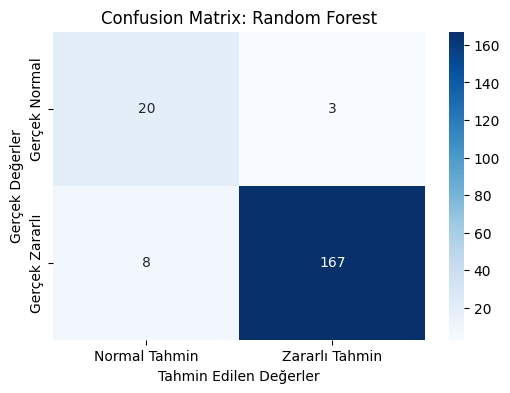


SONUÇLAR: SVM
              precision    recall  f1-score   support

  Normal (0)       0.59      0.70      0.64        23
 Zararlı (1)       0.96      0.94      0.95       175

    accuracy                           0.91       198
   macro avg       0.78      0.82      0.79       198
weighted avg       0.92      0.91      0.91       198



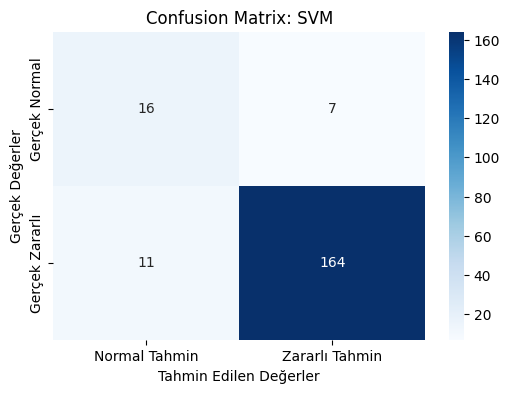


SONUÇLAR: Derin Öğrenme (MLP)
              precision    recall  f1-score   support

  Normal (0)       0.61      0.74      0.67        23
 Zararlı (1)       0.96      0.94      0.95       175

    accuracy                           0.91       198
   macro avg       0.79      0.84      0.81       198
weighted avg       0.92      0.91      0.92       198



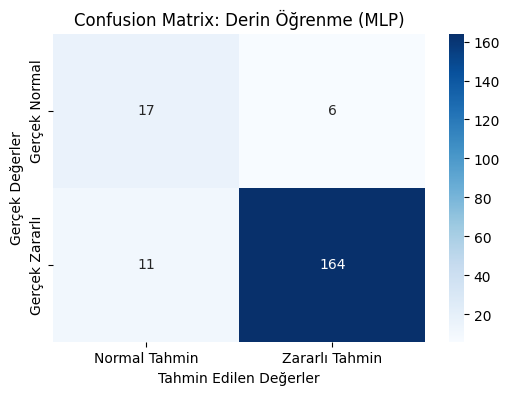


SONUÇLAR: Isolation Forest
              precision    recall  f1-score   support

  Normal (0)       0.06      0.43      0.10        23
 Zararlı (1)       0.52      0.08      0.14       175

    accuracy                           0.12       198
   macro avg       0.29      0.26      0.12       198
weighted avg       0.47      0.12      0.13       198



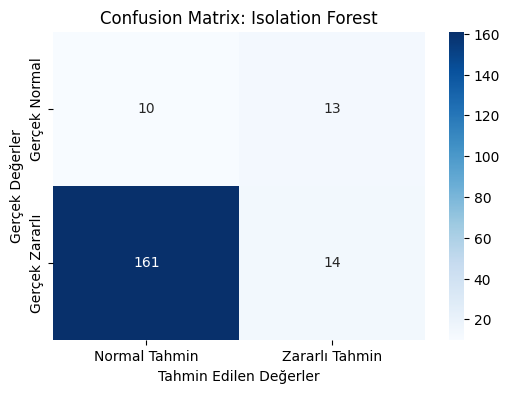


SONUÇLAR: K-Means Clustering
              precision    recall  f1-score   support

  Normal (0)       0.18      0.78      0.29        23
 Zararlı (1)       0.95      0.53      0.68       175

    accuracy                           0.56       198
   macro avg       0.56      0.65      0.48       198
weighted avg       0.86      0.56      0.63       198



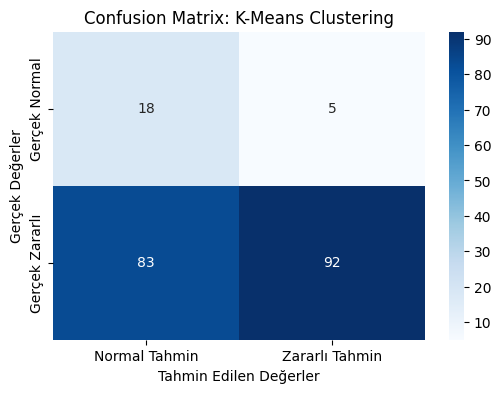


[Autoencoder] Hesaplanan Eşik (Threshold) Değeri: 0.2910

SONUÇLAR: Autoencoder
              precision    recall  f1-score   support

  Normal (0)       0.14      1.00      0.24        23
 Zararlı (1)       1.00      0.17      0.29       175

    accuracy                           0.27       198
   macro avg       0.57      0.59      0.27       198
weighted avg       0.90      0.27      0.29       198



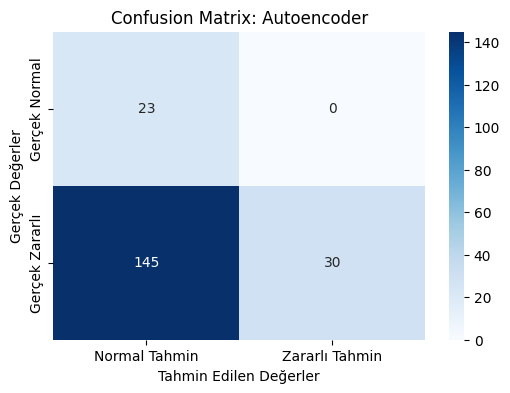

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input

# Grafikler için genel ayar
plt.rcParams['figure.figsize'] = (6, 4)

# ==========================================
# YARDIMCI FONKSİYON: METRİKLER VE CONFUSION MATRIX ÇİZİMİ
# ==========================================
def evaluate_model(y_true, y_pred, model_name):
    print(f"\n{'='*50}")
    print(f"SONUÇLAR: {model_name}")
    print(f"{'='*50}")

    # 1. Performans Metrikleri
    print(classification_report(y_true, y_pred, target_names=["Normal (0)", "Zararlı (1)"], zero_division=0))

    # 2. Confusion Matrix Hesaplama ve Çizimi
    cm = confusion_matrix(y_true, y_pred)

    plt.figure()
    # Isı haritası (Heatmap) oluşturma
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Normal Tahmin", "Zararlı Tahmin"],
                yticklabels=["Gerçek Normal", "Gerçek Zararlı"])
    plt.title(f'Confusion Matrix: {model_name}')
    plt.ylabel('Gerçek Değerler')
    plt.xlabel('Tahmin Edilen Değerler')
    plt.show()

# ==========================================
# 1. VERİ YÜKLEME VE ÖN İŞLEME
# ==========================================
print(">>> Veriler yükleniyor ve ön işleme yapılıyor...")
df_zararli = pd.read_csv('zararli_dataset.csv')
df_normal = pd.read_csv('normal_dataset.csv')

df_zararli['Target'] = 1
df_normal['Target'] = 0
df = pd.concat([df_normal, df_zararli], ignore_index=True)

drop_columns = ['Dosya Adi', 'Zaman Aralığı', 'Baskın Kaynak', 'Baskın Hedef',
                'Paket İçerik Özellikleri(Payload)', 'Gözlemlenen Davranış Örüntüsü', 'Etiket']
df = df.drop(columns=[col for col in drop_columns if col in df.columns])

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = df[col].astype(str)
    df[col] = le.fit_transform(df[col])

df = df.fillna(0)

# ==========================================
# 2. TRAIN-TEST SPLIT, ÖLÇEKLENDİRME VE SMOTE
# ==========================================
X = df.drop(columns=['Target'])
y = df['Target']

# Test seti ayrılıyor (Gerçek verilerle test edeceğiz, SMOTE bulaşmayacak)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n>>> SMOTE ÖNCESİ Eğitim Seti Sınıf Dağılımı:")
print(y_train.value_counts())

# SMOTE Uygulaması (Sadece Eğitim Setine)
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("\n>>> SMOTE SONRASI Eğitim Seti Sınıf Dağılımı (Dengelenmiş):")
print(y_train_resampled.value_counts())
print("-" * 50)


# ==========================================
# A. GÖZETİMLİ ÖĞRENME (SMOTE İLE EĞİTİLMİŞ)
# ==========================================

# 1. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_resampled, y_train_resampled)
rf_preds = rf.predict(X_test_scaled)
evaluate_model(y_test, rf_preds, "Random Forest")

# 2. Support Vector Machine (SVM)
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_resampled, y_train_resampled)
svm_preds = svm.predict(X_test_scaled)
evaluate_model(y_test, svm_preds, "SVM")

# 3. Derin Öğrenme (MLP)
dl_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_resampled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
dl_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
dl_model.fit(X_train_resampled, y_train_resampled, epochs=20, batch_size=32, validation_split=0.2, verbose=0)
dl_probs = dl_model.predict(X_test_scaled, verbose=0)
dl_preds = (dl_probs > 0.5).astype(int).flatten()
evaluate_model(y_test, dl_preds, "Derin Öğrenme (MLP)")


# ==========================================
# B. GÖZETİMSİZ ÖĞRENME (ANOMALİ TESPİTİ)
# ==========================================
# Not: Anomali tespiti modellerini de SMOTE ile çoğaltılmış veriyle eğitiyoruz.

# 1. Isolation Forest
iso = IsolationForest(contamination='auto', random_state=42)
iso.fit(X_train_resampled)
iso_preds = iso.predict(X_test_scaled)
iso_preds = np.where(iso_preds == -1, 1, 0)
evaluate_model(y_test, iso_preds, "Isolation Forest")

# 2. K-Means Clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_preds = kmeans.fit_predict(X_test_scaled)
if accuracy_score(y_test, kmeans_preds) < 0.5:
    kmeans_preds = 1 - kmeans_preds
evaluate_model(y_test, kmeans_preds, "K-Means Clustering")

# 3. Autoencoder
# Autoencoder sadece NORMAL veri ile eğitilir. SMOTE sayesinde artık elimizde
# daha fazla (gerçek + sentetik) normal eğitim verisi var.
X_train_normal_resampled = X_train_resampled[y_train_resampled == 0]

input_dim = X_train_resampled.shape[1]
input_layer = Input(shape=(input_dim,))
encoder = Dense(16, activation="relu")(input_layer)
encoder = Dense(8, activation="relu")(encoder)
decoder = Dense(16, activation="relu")(encoder)
decoder = Dense(input_dim, activation="linear")(decoder)

autoencoder = Model(inputs=input_layer, outputs=decoder)
autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.fit(X_train_normal_resampled, X_train_normal_resampled, epochs=20, batch_size=32, shuffle=True, verbose=0)

reconstructions = autoencoder.predict(X_test_scaled, verbose=0)
mse = np.mean(np.power(X_test_scaled - reconstructions, 2), axis=1)

normal_mse = np.mean(np.power(X_train_normal_resampled - autoencoder.predict(X_train_normal_resampled, verbose=0), 2), axis=1)
threshold = np.mean(normal_mse) + (3 * np.std(normal_mse))

ae_preds = (mse > threshold).astype(int)
print(f"\n[Autoencoder] Hesaplanan Eşik (Threshold) Değeri: {threshold:.4f}")
evaluate_model(y_test, ae_preds, "Autoencoder")